# Textbook Code for Sections 5.1.5 and 5.2

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import root
from scipy.signal import find_peaks

In [2]:
# Main HH Integrator

def deriv(t,y):
    v, n, m, h = y
    vd = (1.0/cm) * (-gk * (n**4) * (v-vk) - gna * (m**3) * h * (v-vna) - gl * (v-vl) + Iapp)
    md = alpham(v) * (1.0-m) - betam(v) * m
    hd = alphah(v) * (1.0-h) - betah(v) * h
    nd = alphan(v) * (1.0-n) - betan(v) * n
    return [vd, nd, md, hd]

def alpham(v):
    return 0.1 * (25.0-v) / (np.exp((25.0 - v) / 10.0) - 1.0)
def betam(v):
    return 4.0 * np.exp(-(v)/18.0)
def alphan(v):
    return 0.01 * (10.0-v) / (np.exp((10.0 - v) / 10.0) - 1.0)
def betan(v):
    return 0.125 * np.exp(-(v)/80.0)
def alphah(v):
    return 0.07 * np.exp(-(v)/20.0)
def betah(v):
    return 1.0 / (np.exp((30.0 - v) / 10.0) + 1.0)

## No Oscillations ($I_{app}<HB_1$)

Text(0.5, 1.0, '$I_{app}=0.2$, No Oscillations')

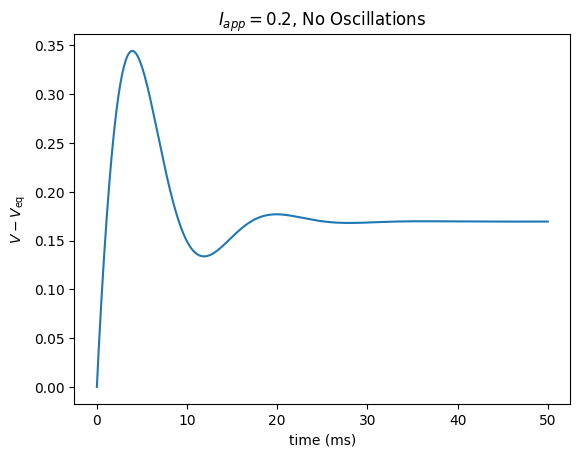

In [3]:
# initial conditions
v0 = 0
n0 = 0.31768
m0 = 0.052934
h0 = 0.59611

# the parameters
Iapp = 0.2
gna = 120.0
gk = 36.0
gl = 0.3
vna = 115.0
vk = -12.0
vl = 10.6
cm = 1.0

# solve the odes
y0 = [v0, n0, m0, h0] 
tout = np.linspace(0, 50, 500)
soln = solve_ivp(deriv, [0, 50], y0, method = 'Radau', t_eval = tout, rtol = 10e-6, atol = 10e-9)

# plot the solution
plt.plot(soln.t, soln.y[0])
plt.xlabel(r'time (ms)')
plt.ylabel(r'$V-V_{\rm eq}$')
plt.title(r"$I_{app}=0.2$, No Oscillations")

## Oscillations ($I_{app}$ in Hopf Bifurcation Interval)

We will do it for $I_{app}$ smaller, such as $20$, and larger, such as $140$, as done in the textbook, to display different amplitudes of oscillations, determined by the distance between the two stable limit cycle branches.

Text(0.5, 1.0, '$I_{app}=20$, Sharper Oscillations with Larger Amplitudes')

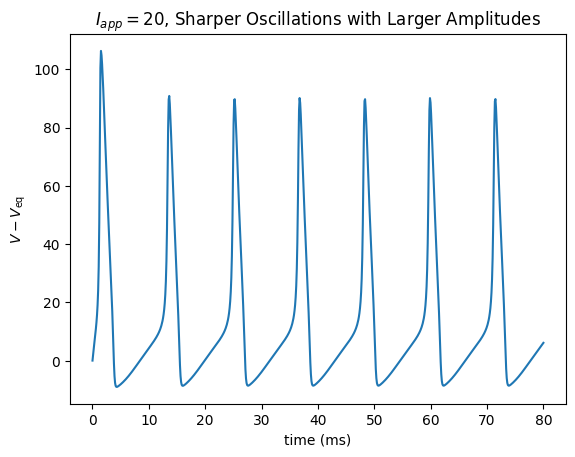

In [4]:
# Iapp = 20
Iapp = 20
y0 = [v0, n0, m0, h0] 
tout = np.linspace(0, 80, 800)
soln = solve_ivp(deriv, [0, 80], y0, method = 'Radau', t_eval = tout, rtol = 10e-6, atol = 10e-9)

# plot the solution
plt.plot(soln.t, soln.y[0])
plt.xlabel(r'time (ms)')
plt.ylabel(r'$V-V_{\rm eq}$')
plt.title(r"$I_{app}=20$, Sharper Oscillations with Larger Amplitudes")

Text(0.5, 1.0, '$I_{app}=140$, Oscillations Eventually Become Smaller')

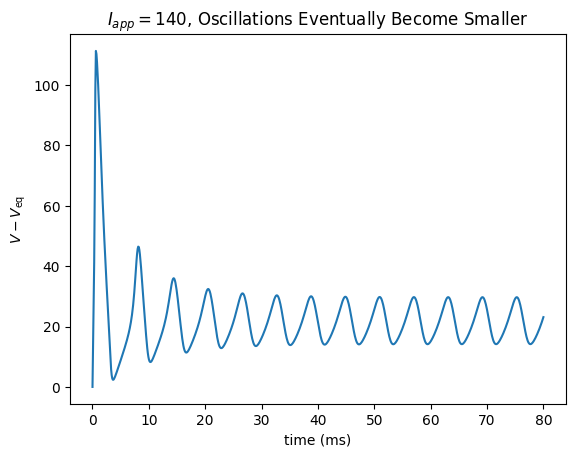

In [5]:
# Iapp = 140
Iapp = 140
y0 = [v0, n0, m0, h0] 
tout = np.linspace(0, 80, 800)
soln = solve_ivp(deriv, [0, 80], y0, method = 'Radau', t_eval = tout, rtol = 10e-6, atol = 10e-9)

# plot the solution
plt.plot(soln.t, soln.y[0])
plt.xlabel(r'time (ms)')
plt.ylabel(r'$V-V_{\rm eq}$')
plt.title(r"$I_{app}=140$, Oscillations Eventually Become Smaller")

## No Oscillations ($I_{app}>HB_2$)

Text(0.5, 1.0, '$I_{app}=250$')

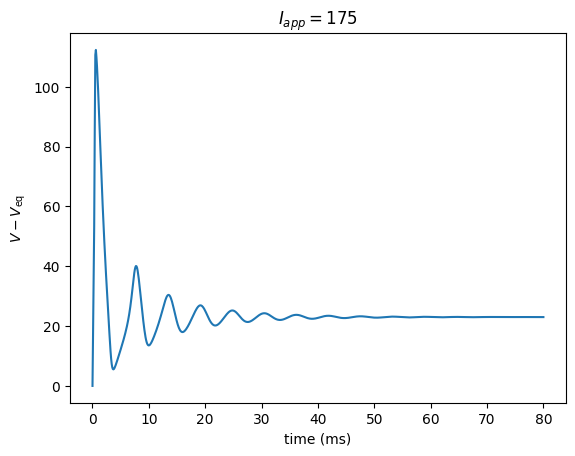

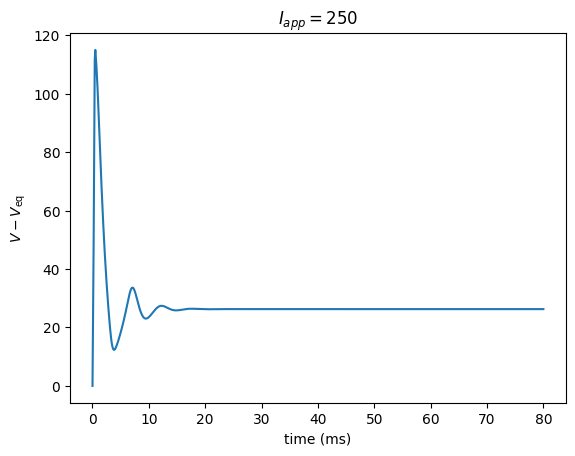

In [6]:
# We try for I_app > 160 to see if that is enough
# Iapp = 175
Iapp = 175
y0 = [v0, n0, m0, h0] 
tout = np.linspace(0, 80, 800)
soln = solve_ivp(deriv, [0, 80], y0, method = 'Radau', t_eval = tout, rtol = 10e-6, atol = 10e-9)

# plot the solution
plt.plot(soln.t, soln.y[0])
plt.xlabel(r'time (ms)')
plt.ylabel(r'$V-V_{\rm eq}$')
plt.title(r"$I_{app}=175$")

# Iapp = 250
Iapp = 250
y0 = [v0, n0, m0, h0] 
tout = np.linspace(0, 80, 800)
soln = solve_ivp(deriv, [0, 80], y0, method = 'Radau', t_eval = tout, rtol = 10e-6, atol = 10e-9)

# plot the solution
plt.figure(2)
plt.plot(soln.t, soln.y[0])
plt.xlabel(r'time (ms)')
plt.ylabel(r'$V-V_{\rm eq}$')
plt.title(r"$I_{app}=250$")

These are essentially the plots for Figure 5.11B. I will try to do 5.11A at some point but that would likely require PyDSTool for example, or I can try some other tools as well.

For the interpretation, if our $I_{app}$ lies below the Hopf bifurcation interval, the single solution is a steady state so the time series typically will settle and not oscillate. The same happens when $I_{app}$ lies above the Hopf interval. For $I_{app}$ in between, there are oscillations due to being in a limit cycle; the amplitude is determined by the distance between the lower and upper branches of the stable limit cycle at that value of $I_{app}$, and in theory the period should be approximated as $$T\approx\dfrac{2\pi}{\Im(\lambda)}.$$

----
# FitzHugh-Nagumo Equations

This model is a simplification of the HH model, done so by separating the two time scales and combining some of HH model parameters into ones characterised by the time scale (reducing the dimension from $4\to2$. Then, we can use the phase plane to analyse the trajectory with respect to the fast and slow variable, which in some cases turns out to contain a relaxation oscillation, where the oscillation is very fast in one part of the cycle then very slow in the next.

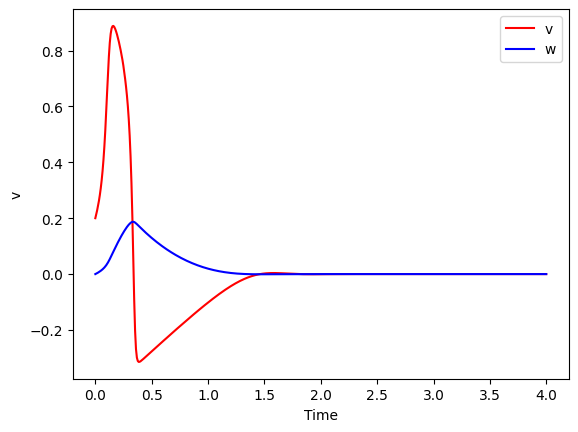

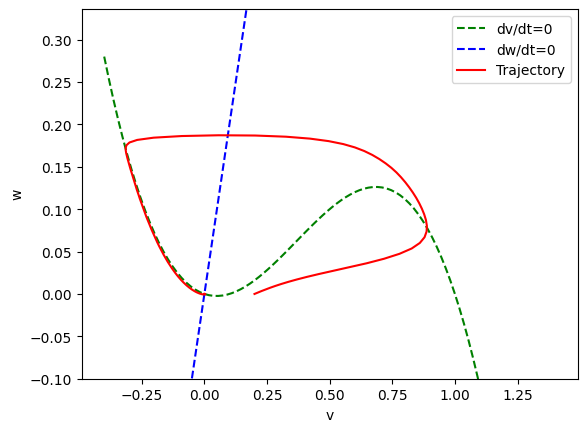

In [7]:
# Code for Figure 5.15
def fhnrhs(t, x):
    v, w = x
    dvdt = (v * (alpha - v) * (v - 1) - w + Iapp) / eps
    dwdt = v - gamma * w
    return [dvdt, dwdt]

eps = 0.01
alpha = 0.1
gamma = 0.5
Iapp = 0

t_span = (0, 4)
tout = np.linspace(0,4,500)
initial_conditions = [0.2, 0]

sol = solve_ivp(fhnrhs, t_span, initial_conditions,t_eval=tout)

# Plotting
plt.figure(1)
plt.plot(sol.t, sol.y[0], 'r', label='v')
plt.plot(sol.t, sol.y[1], 'b', label='w')
plt.xlabel('Time')
plt.ylabel('v')
plt.legend()

plt.figure(2)
v = np.linspace(-0.4, 1.4, 100)
w1 = v * (alpha - v) * (v - 1) + Iapp
w2 = v / gamma
plt.plot(v, w1, 'g--', label='dv/dt=0')
plt.plot(v, w2, 'b--', label='dw/dt=0')
plt.plot(sol.y[0], sol.y[1], 'r', label='Trajectory')
plt.ylim([-0.1, 1.2 * max(w1)])
plt.xlabel('v')
plt.ylabel('w')
plt.legend()

plt.show()

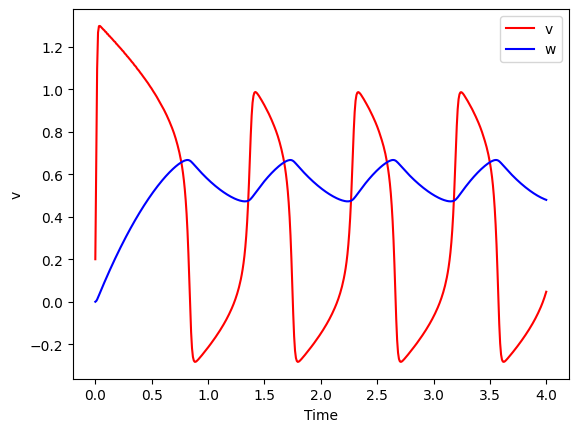

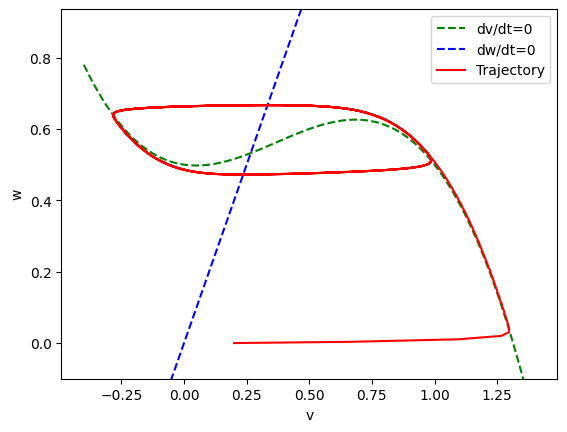

In [10]:
# Figure 5.16, main difference is I_app is nonzero now, which may have triggered the Hopf

eps = 0.01
alpha = 0.1
gamma = 0.5
Iapp = 0.5

t_span = (0, 4)
tout = np.linspace(0,4,500)
initial_conditions = [0.2, 0]

sol = solve_ivp(fhnrhs, t_span, initial_conditions,t_eval=tout)

# Plotting
plt.figure(1)
plt.plot(sol.t, sol.y[0], 'r', label='v')
plt.plot(sol.t, sol.y[1], 'b', label='w')
plt.xlabel('Time')
plt.ylabel('v')
plt.legend()

plt.figure(2)
v = np.linspace(-0.4, 1.4, 100)
w1 = v * (alpha - v) * (v - 1) + Iapp
w2 = v / gamma
plt.plot(v, w1, 'g--', label='dv/dt=0')
plt.plot(v, w2, 'b--', label='dw/dt=0')
plt.plot(sol.y[0], sol.y[1], 'r', label='Trajectory')
plt.ylim([-0.1, 1.2 * max(w1)])
plt.xlabel('v')
plt.ylabel('w')
plt.legend()

plt.show()

What it seems to be doing is that, since we started from (0.2, 0) the trajectory would follow in the direction delineated by the nullclines (up/down and left/right) so in this case it comes very close to the $dv/dt=0$ nullcline at some point and that is what starts the oscillation as it seems that the trajectory is pushed towards the main area (could try to check this analytically by determining where the derivatives are +ve or -ve.

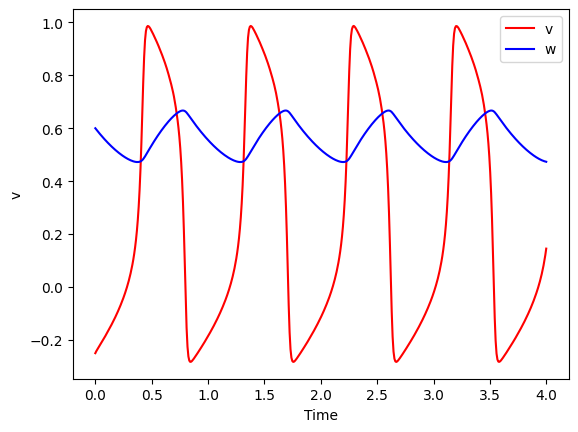

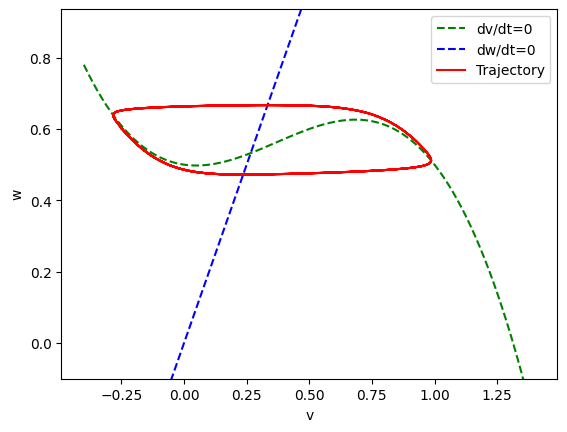

In [11]:
# If we started on the cycle region, not exactly on it but closer. To get an exact value 
# We may need to do some more computation

eps = 0.01
alpha = 0.1
gamma = 0.5
Iapp = 0.5

t_span = (0, 4)
tout = np.linspace(0,4,500)
initial_conditions = [-0.25, 0.6]

sol = solve_ivp(fhnrhs, t_span, initial_conditions,t_eval=tout)

# Plotting
plt.figure(1)
plt.plot(sol.t, sol.y[0], 'r', label='v')
plt.plot(sol.t, sol.y[1], 'b', label='w')
plt.xlabel('Time')
plt.ylabel('v')
plt.legend()

plt.figure(2)
v = np.linspace(-0.4, 1.4, 100)
w1 = v * (alpha - v) * (v - 1) + Iapp
w2 = v / gamma
plt.plot(v, w1, 'g--', label='dv/dt=0')
plt.plot(v, w2, 'b--', label='dw/dt=0')
plt.plot(sol.y[0], sol.y[1], 'r', label='Trajectory')
plt.ylim([-0.1, 1.2 * max(w1)])
plt.xlabel('v')
plt.ylabel('w')
plt.legend()

plt.show()

## Bifurcation Diagram

I will try to convert the `fhn.ode` file's code into something in Python. I don't really want to use PyDSTool for now but I will use it if I must, for now will use numpy and scipy.

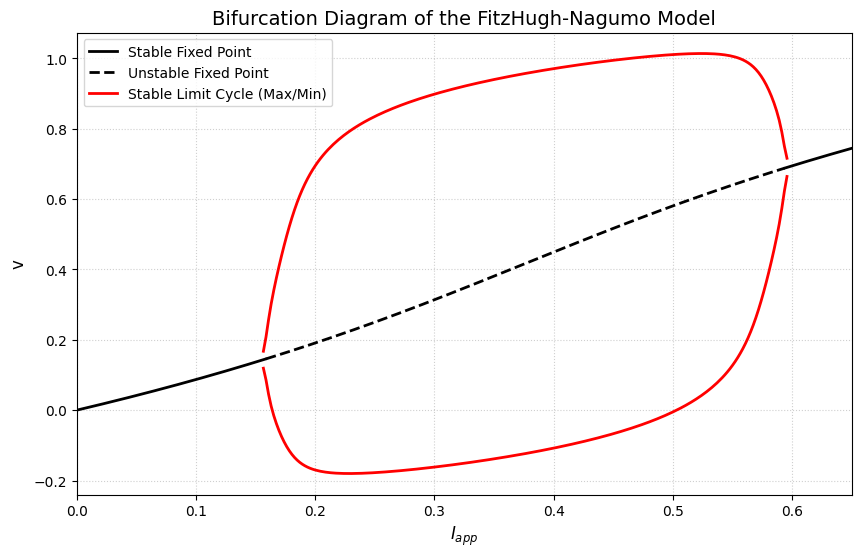

In [12]:
# Model parameters and equations
a, eps, gamma = 0.25, 0.05, 1.0

def f(v):
    return v * (1 - v) * (v - a)

def fitzhugh_nagumo(t, y, I0):
    v, w = y
    return [f(v) - w + I0, eps * (v - gamma * w)]

def jacobian(v, w):
    df_dv = -3 * v**2 + 2 * (a + 1) * v - a
    return np.array([[df_dv, -1.0], [eps, -eps * gamma]])

I_max = 0.65 

# Fixed points and stability
I_range = np.linspace(0.0, I_max, 1500)
I_stable, eq_v_stable = [], []
I_unstable, eq_v_unstable = [], []

v_guess, w_guess = 0.0, 0.0
for I0 in I_range:
    sol = root(lambda y: fitzhugh_nagumo(0, y, I0), [v_guess, w_guess])
    if sol.success:
        v_eq, w_eq = sol.x
        v_guess, w_guess = v_eq, w_eq 
        
        eigenvalues = np.linalg.eigvals(jacobian(v_eq, w_eq))
        max_real_eigenvalue = np.max(np.real(eigenvalues))
        
        if max_real_eigenvalue < -1e-5:
            I_stable.append(I0)
            eq_v_stable.append(v_eq)
        else:
            I_unstable.append(I0)
            eq_v_unstable.append(v_eq)
            
# Brute force simulation
I_sweep = np.linspace(0.0, I_max, 300) 
t_span = (0, 800) 

orbit_I = []
orbit_v_max = []
orbit_v_min = []

for I0 in I_sweep:
    res = solve_ivp(fitzhugh_nagumo, t_span, [0.1, 0.0], args=(I0,), 
                    dense_output=True, rtol=1e-8, atol=1e-10)
    
    t_eval = np.linspace(700, 800, 3000)
    v_trajectory = res.sol(t_eval)[0]
    
    if np.var(v_trajectory) > 1e-4:
        peaks, _ = find_peaks(v_trajectory)
        valleys, _ = find_peaks(-v_trajectory)
        
        if len(peaks) > 0 and len(valleys) > 0:
            orbit_I.append(I0)
            orbit_v_max.append(v_trajectory[peaks[-1]])
            orbit_v_min.append(v_trajectory[valleys[-1]])


# Plotting
plt.figure(figsize=(10, 6))

# Helper to find where continuous segments break or switch
def plot_segments(I_data, v_data, is_stable=True):
    if not I_data:
        return
    # Find gaps in indices to handle split segments cleanly
    I_data = np.array(I_data)
    v_data = np.array(v_data)
    
    # We find where the parameter jump is large to detect a segment split
    diffs = np.diff(I_data)
    # Threshold based on our linspace resolution (I_max / 1500 * 2)
    split_indices = np.where(diffs > 0.002)[0] + 1
    
    I_splits = np.split(I_data, split_indices)
    v_splits = np.split(v_data, split_indices)
    
    label_added = False
    for i, (I_seg, v_seg) in enumerate(zip(I_splits, v_splits)):
        if len(I_seg) == 0:
            continue
        linestyle = '-' if is_stable else '--'
        label = ('Stable Fixed Point' if is_stable else 'Unstable Fixed Point') if not label_added else ""
        plt.plot(I_seg, v_seg, color='black', linestyle=linestyle, linewidth=2, label=label)
        label_added = True

# Plot the equilibria cleanly as actual line segments
plot_segments(I_stable, eq_v_stable, is_stable=True)
plot_segments(I_unstable, eq_v_unstable, is_stable=False)

# Plot the limit cycles
if orbit_I:
    plt.plot(orbit_I, orbit_v_max, color='red', linewidth=2, label='Stable Limit Cycle (Max/Min)')
    plt.plot(orbit_I, orbit_v_min, color='red', linewidth=2)

plt.title('Bifurcation Diagram of the FitzHugh-Nagumo Model', fontsize=14)
plt.xlabel(r'$I_{app}$', fontsize=12)
plt.ylabel('v', fontsize=12)
plt.xlim(0.0, I_max)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left')
plt.show()


I think given the fact that we did not use PyDSTool for this, it is decently close to Figure 5.17; maybe not as smooth although this is using brute force rather than continuations. After some searching, it seems that AUTO uses this algorithm called "pseudo-arclength continuation" (or more generally [numerical continuation](https://en.wikipedia.org/wiki/Numerical_continuation)) which traces the solutions on the curve as the control parameter changes. That is why we can get more "exact" tracking for bifurcation analysis if we use PyDSTool which uses continuation. More specifically, PyDSTool uses an AUTO wrapper called `PyCont`.